## Neural Networks

In [1]:
import sklearn
import numpy as np
import pandas
print("sklearn:", sklearn.__version__)
print("numpy:", np.__version__)
print("pandas:", pandas.__version__)

sklearn: 1.9.0
numpy: 2.5.2
pandas: 3.0.5


### Data

In [2]:
iris = sklearn.datasets.load_iris()
X, y = iris["data"], iris["target"] # Splittar features mot target(Svar)

### Panda dataframe

In [3]:
df = pandas.DataFrame(
    np.column_stack((X, y)),
    columns=np.append(iris["feature_names"], ["target"]),
)

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [4]:
number_Setosa = df[df["target"] == 0.0].shape[0]
number_Versicolor = df[df["target"] == 1.0].shape[0]
number_Virginica = df[df["target"] == 2.0].shape[0]

print("Setosa   :", number_Setosa)
print("Number Versicolor:", number_Versicolor)
print("Number Virginica:", number_Virginica)
print(21 * "-")
print("Total number    :", df.shape[0])

Setosa   : 50
Number Versicolor: 50
Number Virginica: 50
---------------------
Total number    : 150


### Neural network function

In [8]:
def mlp_model(tuning):
    ### Splitar test och non-test
    X_train_validation, X_test, y_train_validation, y_test = sklearn.model_selection.train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=67
    )

    if tuning:
        ### Splitar training och validation
        X_train, X_eval, y_train, y_eval = sklearn.model_selection.train_test_split(
            X_train_validation,
            y_train_validation,
            test_size=0.20,
            stratify=y_train_validation,
            random_state=67
        )
        print("Training:", X_train.shape)
        print("Validation:", X_eval.shape)
        print("Test:", X_test.shape)
    else:
        X_train, y_train = X_train_validation, y_train_validation
        X_eval, y_eval = X_test, y_test
        print("Training:", X_train.shape)
        print("Test:", X_eval.shape)

    ### Scalar datat
    scaler = sklearn.preprocessing.StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train)
    X_eval_scaled = scaler.transform(X_eval)

    df_train_scaled = pandas.DataFrame(
        np.column_stack((X_train_scaled, y_train)),
        columns=np.append(iris["feature_names"], ["target"]),
    )
    print(df_train_scaled)

    ### gör network
    mlp = sklearn.neural_network.MLPClassifier(
        hidden_layer_sizes=(6, 6),
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=67,
    )

    mlp.fit(X_train_scaled, y_train)

    for i, (W, b) in enumerate(zip(mlp.coefs_, mlp.intercepts_)):
        print(f"Layer {i}: weights = {W.shape}, biases = {b.shape}")

    n_params = sum(w.size for w in mlp.coefs_) + sum(b.size for b in mlp.intercepts_)
    print("Number of parameters:", n_params)

    ### Modell evaluation
    y_pred = mlp.predict(X_eval_scaled)

    ### Classification
    print(sklearn.metrics.classification_report(y_eval, y_pred, target_names=iris["target_names"]))

    ### Confusion matrix
    import matplotlib.pyplot as plt

    cm = sklearn.metrics.confusion_matrix(y_eval, y_pred)

    disp = sklearn.metrics.ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris["target_names"])
    disp.plot(cmap=plt.cm.Blues)

    plt.title("MLP Confusion Matrix")
    plt.show()

    print(mlp.out_activation_)

    return sklearn.metrics.f1_score(y_eval, y_pred, average="macro")

### Tuning (training / validation)

Training: (96, 4)
Validation: (24, 4)
Test: (30, 4)
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0           -0.426101         -1.072390           0.364841         -0.012397   
1            0.682788          0.288175           0.879912          1.442177   
2           -0.918940          1.648741          -1.237599         -1.334737   
3           -1.411779          0.288175          -1.409290         -1.334737   
4            0.559578          0.741697           1.051602          1.574412   
..                ...               ...                ...               ...   
91          -0.549311         -0.165347           0.422071          0.384305   
92          -0.918940          0.968458          -1.352060         -1.334737   
93          -0.426101         -1.525912          -0.035769         -0.276865   
94           0.682788         -0.392108           0.307611          0.119837   
95           1.052417          0.061414           0.536532          

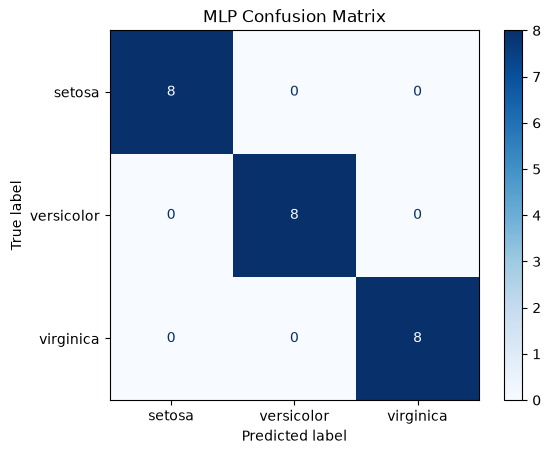

softmax
Macro-F1 (validation): 1.0


In [9]:
macro_f1_validation = mlp_model(tuning=True)
print("Macro-F1 (validation):", macro_f1_validation)

### Final evaluation (training / test)

Training: (120, 4)
Test: (30, 4)
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0             0.632796         -0.795694           0.686152          0.804169   
1             1.389628          0.109361           0.686152          0.406503   
2            -1.133146          1.240679          -1.343312         -1.449272   
3             0.632796         -0.343167           1.092045          0.804169   
4            -1.259285          0.109361          -1.227342         -1.316716   
..                 ...               ...                ...               ...   
115          -1.133146         -1.248221           0.454213          0.671614   
116           0.002102          2.145734          -1.459281         -1.316716   
117           1.389628          0.109361           0.802121          1.466946   
118          -0.754730          0.788152          -1.343312         -1.316716   
119          -0.250175         -0.569430           0.686152          1.06928

/Users/astridlithell/miniconda3/envs/cb1020/lib/python3.14t/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


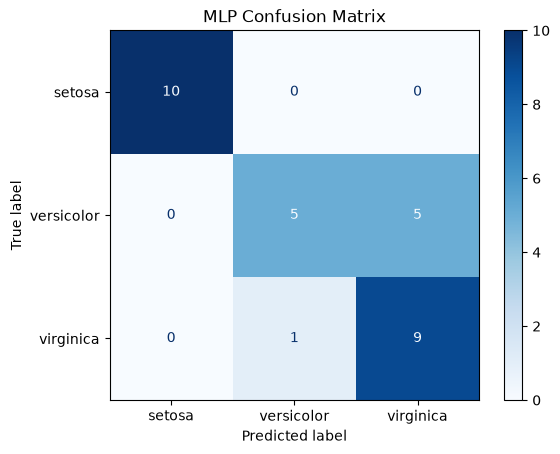

softmax
Macro-F1 (test): 0.7916666666666666


In [7]:
macro_f1_test = mlp_model(tuning=False)
print("Macro-F1 (test):", macro_f1_test)